# [기초-실습] 통계 101×데이터 분석: (7장) 상관과 회귀

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비

### 1단계 · 한글 폰트 설치

- 그래프에 한글이 깨지지 않도록 나눔 폰트를 설치합니다.

- 실행 후 **[런타임] - [세션 다시 시작]**을 한 번 눌러야 폰트가 적용됩니다.

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

You should consider upgrading via the 'C:\Users\user\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.
Sudo가 이 컴퓨터에서 사용하지 않도록 설정되어 있습니다. 사용하도록 설정하려면 으로 이동하세요. ]8;;ms-settings:developers\Developer Settings page]8;;\ 설정 앱의
Sudo가 이 컴퓨터에서 사용하지 않도록 설정되어 있습니다. 사용하도록 설정하려면 으로 이동하세요. ]8;;ms-settings:developers\Developer Settings page]8;;\ 설정 앱의
'rm'��(��) ���� �Ǵ� �ܺ� ����, ������ �� �ִ� ���α׷�, �Ǵ�
��ġ ������ �ƴմϴ�.


### 2단계 · 라이브러리 불러오기

- 이번 실습에서 쓰는 도구입니다. **한 번만 실행**해 두면 끝까지 사용합니다.

- `smf`는 회귀식을 `'y ~ x'` 형태로 쓰는 모듈, `het_breuschpagan`은 등분산 검정 함수입니다.

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

## 문제 1 · 펭귄의 부리는 길수록 두꺼울까?

`난이도 하` · `예상 15분`

**📖 상황**

- 남극 팔머 기지에서 측정한 펭귄 344마리의 신체 데이터(`penguins`)를 사용합니다.

- 부리 길이(`bill_length_mm`)와 부리 두께(`bill_depth_mm`)가 함께 어떻게 움직이는지 봅니다.

- 그런데 이 데이터에는 **세 종(Adelie·Chinstrap·Gentoo)이 섞여 있습니다.**
  전체를 뭉쳐서 볼 때와 집단을 나눠서 볼 때 **결론이 정반대로 뒤집히는 일**이 실제로 일어납니다.

**🎯 이 문제로 배우는 것**

- 상관계수를 계산하기 **전에** 산점도를 먼저 그려야 하는 이유를, 숫자로 직접 확인합니다.

In [3]:
# 문제 1 · 데이터 준비 — 실행만 하세요
penguins = sns.load_dataset('penguins')

print("데이터 크기:", penguins.shape)
print("\n종별 개체 수:")
print(penguins['species'].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())

penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### Q1 · 산점도로 두 변수의 관계를 그려 봅시다

- 가로축 `bill_length_mm`, 세로축 `bill_depth_mm`로 산점도를 그리세요.

- 그래프 제목과 축 라벨을 한글로 알아보기 쉽게 설정하세요.

- `💡 힌트` `sns.scatterplot(data=..., x=..., y=...)` / `plt.title()`, `plt.xlabel()`, `plt.ylabel()`

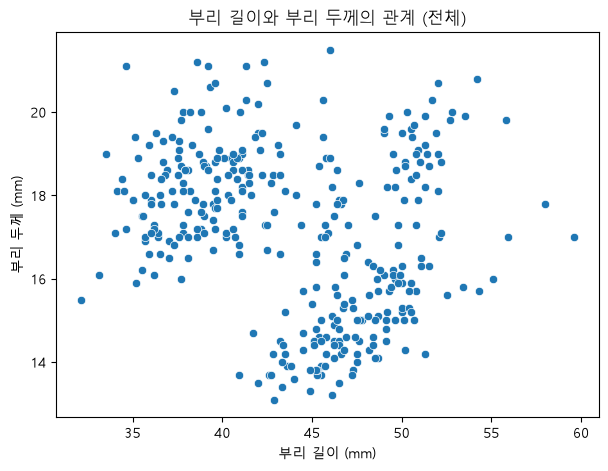

In [ ]:
# 문제 1 · Q1
# 여기에 코드를 작성해주세요.
plt.rcParams['font.family'] = 'Malgun Gothic'   # Mac: 'AppleGothic', Colab: 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(7, 5))
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')
plt.title('부리 길이와 부리 두께의 관계 (전체)')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q2 · 종별로 색을 나눠 같은 그림을 다시 그려 봅시다

- Q1과 똑같은 산점도에 펭귄의 종(`species`)별로 점의 색을 다르게 칠하세요.

- Q1의 그림과 나란히 놓고 무엇이 달라 보이는지 관찰하세요.

- `💡 힌트` `sns.scatterplot()`에 `hue` 인수를 추가해 보세요.

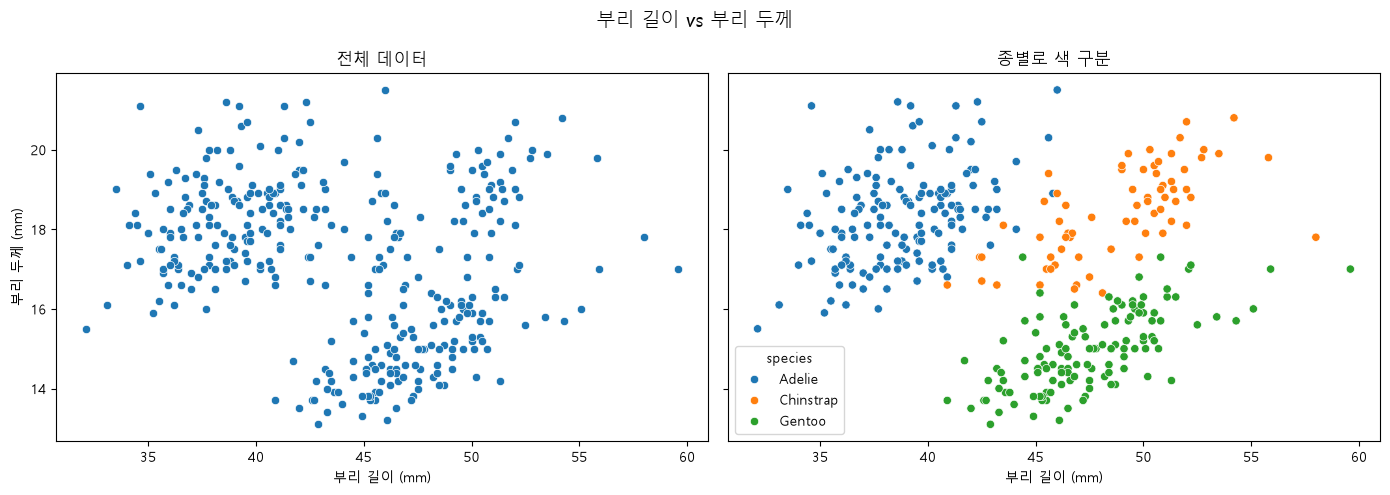

In [6]:
# 문제 1 · Q2
# 여기에 코드를 작성해주세요.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

# 왼쪽: 전체 (Q1)
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', ax=axes[0])
axes[0].set_title('전체 데이터')

# 오른쪽: 종별 색 구분
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
                hue='species', ax=axes[1])
axes[1].set_title('종별로 색 구분')

for ax in axes:
    ax.set_xlabel('부리 길이 (mm)')
    ax.set_ylabel('부리 두께 (mm)')

plt.suptitle('부리 길이 vs 부리 두께', fontsize=14)
plt.tight_layout()
plt.show()

### Q3 · 상관계수를 '전체'와 '종별'로 각각 구해 비교해 봅시다

- 두 변수의 상관계수를 **전체 데이터**에 대해 계산하세요.

- 같은 상관계수를 **종별로 나누어** 계산하세요.

- 두 결과의 **부호**를 비교하세요.

- `💡 힌트` 전체는 `df[['A','B']].dropna().corr()`,
  종별은 `df.groupby('species')[['A','B']].corr()`를 활용해 보세요.

In [7]:
# 문제 1 · Q3
# 여기에 코드를 작성해주세요.
cols = ['bill_length_mm', 'bill_depth_mm']

# 1) 전체 데이터
overall_r = penguins[cols].dropna().corr().loc['bill_length_mm', 'bill_depth_mm']
print(f"전체 상관계수: {overall_r:.3f}")

# 2) 종별 데이터
species_corr = penguins.groupby('species')[cols].corr()
print("\n종별 상관행렬:")
print(species_corr)

# 필요한 값만 뽑아서 표로 정리
species_r = species_corr.xs('bill_length_mm', level=1)['bill_depth_mm']

result = pd.DataFrame({
    '상관계수': species_r.round(3),
    '부호': species_r.apply(lambda r: '양(+)' if r > 0 else '음(-)')
})
result.loc['전체'] = [round(overall_r, 3), '양(+)' if overall_r > 0 else '음(-)']
print("\n비교 결과:")
print(result)

전체 상관계수: -0.235

종별 상관행렬:
                          bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000

비교 결과:
            상관계수    부호
species               
Adelie     0.391  양(+)
Chinstrap  0.654  양(+)
Gentoo     0.643  양(+)
전체        -0.235  음(-)


### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 산점도에서 두 변수는 어떤 방향의 관계로 보였나요? Q3의 전체 상관계수와 부호가 일치하나요?

- Q3의 종별 상관계수는 전체와 부호가 같나요, 다른가요?

- **같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유**를 설명해 보세요. 무엇이 이 착시를 만들고 있나요?

- 만약 이 데이터에 '종' 정보가 없었다면 우리는 어떤 잘못된 결론을 내렸을까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 부호가 뒤집히는 열쇠는 **종마다 부리의 '기본 크기'가 다르다**는 데 있습니다. 종별 평균이 어디에 놓여 있는지를 Q2의 그림에서 확인해 보세요.

- "전체를 보면 음, 나누면 양"은 두 변수 사이에 **숨은 집단 변수**가 끼어 있을 때 나타납니다. 이 현상에는 이름이 붙어 있고, 다음 시간 인과추론에서 다시 만납니다.

- 결론의 형태를 이렇게 나눠 써 보면 정확해집니다 — "종을 무시하면 ○○, 종을 고려하면 ○○".

</details>

In [10]:
# 문제 1 · 정리
# 여기에 의견을 작성해주세요.
print('''
1. 산점도에서는 점들이 덩어리로 흩어져 있어 뚜렷한 직선 관계는 보이지 않았다. 굳이 말하면 약한 음의 상관관계로 보였다. q3에서 상관계수를 구한 결과 -0.235로 이와 일치한다.

2. 종별 상관계수는 3종 0.39, 0.65, 0.64로 모두 양의 상관계수로 전체와 부호가 반대이다.

3. 종마다 부리의 기본 크기 즉 평균의 위치가 다르기 때문이다. 각 종 안에서는 부리가 길수록 두꺼운 양의 관계를 가지고 있다. 
하지만 세 종을 합치면 adelie는 왼쪽 위에, gentoo는 오른쪽 아래에 위치하게 되면서 종과 종 사이의 차이로 인해서 발생하는 음의 방향 추세가 종 내부의 양의 추세를 덮어버리게 된다.
즉, 종이라는 집단 변수가 두 변수 모두에 영향을 주면서 착시를 만들었다.
(심슨의 역설: 여러 집단에서 각각 나타나는 경향이 집단을 합치면 약해지거나 반대로 뒤집히는 현상. 집단을 나누는 변수가 두 변수 모두와 관련되어 있을 때 발생)

4. 종 정보가 없었다면 "펭귄은 부리가 길수록 부리가 얇아진다"는 잘못된 결론을 내렸을 것이다. 하지만 종을 무시하면 음의 관계, 종을 고려하면 세 종 모두 양의 관계이다. 
전체에서 보인 음의 관계는 개체의 특성이 아니라 종 구성의 차이가 만든 착시이다. 따라서 상관계수를 계산하기 전에 산점도를 그려 숨은 집단이 있는지 먼저 확인해야 한다.
''')


1. 산점도에서는 점들이 덩어리로 흩어져 있어 뚜렷한 직선 관계는 보이지 않았다. 굳이 말하면 약한 음의 상관관계로 보였다. q3에서 상관계수를 구한 결과 -0.235로 이와 일치한다.

2. 종별 상관계수는 3종 0.39, 0.65, 0.64로 모두 양의 상관계수로 전체와 부호가 반대이다.

3. 종마다 부리의 기본 크기 즉 평균의 위치가 다르기 때문이다. 각 종 안에서는 부리가 길수록 두꺼운 양의 관계를 가지고 있다. 
하지만 세 종을 합치면 adelie는 왼쪽 위에, gentoo는 오른쪽 아래에 위치하게 되면서 종과 종 사이의 차이로 인해서 발생하는 음의 방향 추세가 종 내부의 양의 추세를 덮어버리게 된다.
즉, 종이라는 집단 변수가 두 변수 모두에 영향을 주면서 착시를 만들었다.
(심슨의 역설: 여러 집단에서 각각 나타나는 경향이 집단을 합치면 약해지거나 반대로 뒤집히는 현상. 집단을 나누는 변수가 두 변수 모두와 관련되어 있을 때 발생)

4. 종 정보가 없었다면 "펭귄은 부리가 길수록 부리가 얇아진다"는 잘못된 결론을 내렸을 것이다. 하지만 종을 무시하면 음의 관계, 종을 고려하면 세 종 모두 양의 관계이다. 
전체에서 보인 음의 관계는 개체의 특성이 아니라 종 구성의 차이가 만든 착시이다. 따라서 상관계수를 계산하기 전에 산점도를 그려 숨은 집단이 있는지 먼저 확인해야 한다.



## 문제 2 · 날개가 길면 몸무게도 무거울까? — 관계를 숫자로

`난이도 하` · `예상 20분`

**📖 상황**

- 문제 1에서 "숫자 전에 그림"을 배웠습니다. 이제 관계를 **숫자 하나**로 요약해 봅니다.

- 이번에는 **날개 길이(`flipper_length_mm`)와 몸무게(`body_mass_g`)**를 봅니다.
  이 두 변수는 **문제 5까지 계속 사용**하며, 상관 → 회귀 → 검정 → 진단으로 이어집니다.

- **피어슨 상관계수(r)**는 관계의 방향(부호)과 강도(절대값)를 −1~+1로 나타냅니다.
  다만 피어슨은 **두 변수가 정규분포라는 전제**에 기대는 모수적 방법입니다.

**🎯 이 문제로 배우는 것**

- 정규성 점검 → 피어슨(r과 p-값) → 스피어만 비교의 순서로, **강의에서 배운 절차 그대로** 상관을 구합니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


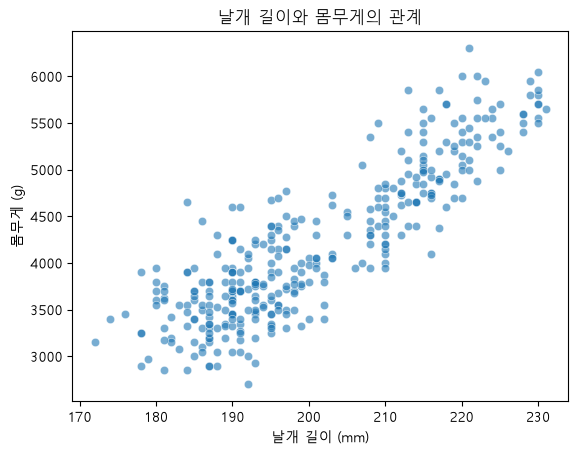

In [11]:
# 문제 2 · 데이터 준비 — 실행만 하세요
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 두 변수의 관계를 그림으로 먼저 확인 (문제 1의 교훈!)
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### Q1 · 피어슨의 전제인 정규성을 점검해 봅시다

- `flipper_length_mm`과 `body_mass_g` **각각**에 대해 정규성 검정(Shapiro-Wilk)을 수행하세요.

- 유의수준 0.05를 기준으로 '정규성을 기각하는지'까지 함께 출력하세요.

- `💡 힌트` `stats.shapiro(데이터)`는 통계량과 p-값을 함께 돌려줍니다.

In [15]:
# 문제 2 · Q1
# 여기에 코드를 작성해주세요.
from scipy import stats

alpha = 0.05
x = df_corr['flipper_length_mm']
y = df_corr['body_mass_g']

stat_flip, p_flip = stats.shapiro(x)
stat_mass, p_mass = stats.shapiro(y)

print(f"[날개 길이] W = {stat_flip:.4f}, p-value = {p_flip:.4e} → "
      f"{'정규성 기각' if p_flip < alpha else '정규성 기각 못 함'}")
print(f"[몸무게]   W = {stat_mass:.4f}, p-value = {p_mass:.4e} → "
      f"{'정규성 기각' if p_mass < alpha else '정규성 기각 못 함'}")

[날개 길이] W = 0.9515, p-value = 3.5401e-09 → 정규성 기각
[몸무게]   W = 0.9592, p-value = 3.6790e-08 → 정규성 기각


### Q2 · 피어슨 상관계수와 p-값을 함께 구해 봅시다

- 상관계수만이 아니라 **p-값도 함께** 구하세요. 상관계수도 가설검정의 대상입니다.

- 결과는 반드시 `r`, `p_value`라는 이름으로 저장하세요. **문제 3·4에서 이어서 사용합니다.**

- `💡 힌트` `r, p_value = stats.pearsonr(x, y)` — 귀무가설은 "모집단의 상관계수가 0이다"입니다.

In [13]:
# 문제 2 · Q2
# 여기에 코드를 작성해주세요.
r, p_value = stats.pearsonr(x, y)

print(f"피어슨 상관계수 r = {r:.4f}")
print(f"p-value = {p_value:.4e}")
print("→ 귀무가설(모상관계수 = 0) 기각" if p_value < alpha else "→ 귀무가설 기각 못 함")

피어슨 상관계수 r = 0.8712
p-value = 4.3707e-107
→ 귀무가설(모상관계수 = 0) 기각


### Q3 · 스피어만 상관계수를 구해 피어슨과 비교해 봅시다

- 스피어만 상관계수(ρ)를 구하세요.

- Q2의 피어슨 값과 **나란히 출력**해 두 값의 차이를 눈으로 확인하세요.

- `💡 힌트` `stats.spearmanr(x, y)`

In [14]:
# 문제 2 · Q3
# 여기에 코드를 작성해주세요.
rho, p_spearman = stats.spearmanr(x, y)

compare = pd.DataFrame({
    '상관계수': [r, rho],
    'p-value': [p_value, p_spearman]
}, index=['피어슨 (r)', '스피어만 (ρ)'])

print(compare.round(4))
print(f"\n두 값의 차이: {abs(r - rho):.4f}")

            상관계수  p-value
피어슨 (r)   0.8712      0.0
스피어만 (ρ)  0.8400      0.0

두 값의 차이: 0.0312


### Q4 · 세 결과를 종합해 관계를 문장으로 정리해 봅시다

- Q1~Q3의 결과를 근거로, 오른쪽 빈칸을 채워 관계를 정리하세요.

- 숫자만 적지 말고 **그 숫자가 뜻하는 바**를 함께 쓰세요.

In [20]:
# 문제 2 · Q4
# 정규성 검정 결과 (피어슨의 전제가 지켜졌나요?):
# 피어슨 r 값과 p-값:
# 스피어만 ρ 값:
# 부호(+/-)가 뜻하는 관계의 방향:
# 절대값의 크기가 뜻하는 관계의 강도:

print(f'''
[정규성 검정 결과 (피어슨의 전제가 지켜졌나요?)]
  날개 길이 p-value = {p_flip:.2e}, 몸무게 p-value = {p_mass:.2e}
  두 변수 모두 p-value < 0.05로 정규성이 기각되었다.
  따라서 피어슨의 전제인 정규성은 지켜지지 않았다.
  (세 종이 섞여 있어 분포의 봉우리가 여러 개 생긴 것이 주된 원인으로 보임)

[피어슨 r 값과 p-값]
  r = {r:.3f}, p-value = {p_value:.2e} (0.05보다 매우 작음)
  → 귀무가설(모상관계수 = 0)을 기각한다. 두 변수의 상관은 통계적으로 유의하다.

[스피어만 ρ 값]
  ρ = {rho:.3f}로 피어슨 r({r:.3f})과 거의 비슷하다.
  정규성을 가정하지 않는 방법으로 구해도 결과가 비슷하므로 정규성 위반이 결론을 바꿀 정도는 아니라고 판단할 수 있다.

[부호(+/-)가 뜻하는 관계의 방향]
  부호가 양(+)이므로 날개가 긴 펭귄일수록 몸무게도 무거운 경향이 있다.

[절대값의 크기가 뜻하는 관계의 강도]
  |r| = {abs(r):.3f}로 1에 가까우므로 강한 선형 관계이다.
  점들이 오른쪽 위로 올라가는 직선 주변에 비교적 촘촘하게 모여 있다는 뜻이다.
''')


[정규성 검정 결과 (피어슨의 전제가 지켜졌나요?)]
  날개 길이 p-value = 3.54e-09, 몸무게 p-value = 3.68e-08
  두 변수 모두 p-value < 0.05로 정규성이 기각되었다.
  따라서 피어슨의 전제인 정규성은 지켜지지 않았다.
  (세 종이 섞여 있어 분포의 봉우리가 여러 개 생긴 것이 주된 원인으로 보임)

[피어슨 r 값과 p-값]
  r = 0.871, p-value = 4.37e-107 (0.05보다 매우 작음)
  → 귀무가설(모상관계수 = 0)을 기각한다. 두 변수의 상관은 통계적으로 유의하다.

[스피어만 ρ 값]
  ρ = 0.840로 피어슨 r(0.871)과 거의 비슷하다.
  정규성을 가정하지 않는 방법으로 구해도 결과가 비슷하므로 정규성 위반이 결론을 바꿀 정도는 아니라고 판단할 수 있다.

[부호(+/-)가 뜻하는 관계의 방향]
  부호가 양(+)이므로 날개가 긴 펭귄일수록 몸무게도 무거운 경향이 있다.

[절대값의 크기가 뜻하는 관계의 강도]
  |r| = 0.871로 1에 가까우므로 강한 선형 관계이다.
  점들이 오른쪽 위로 올라가는 직선 주변에 비교적 촘촘하게 모여 있다는 뜻이다.



### 💬 정리 · 결과를 말로 설명해 보기

- Q1에서 정규성이 기각되었습니다. 그렇다면 피어슨 상관계수를 쓰면 안 되는 걸까요? Q2와 Q3의 값을 비교해서 판단해 보세요.

- 피어슨과 스피어만이 비슷하게 나왔다는 것은 무엇을 뜻할까요? 만약 두 값이 크게 달랐다면 어떤 상황을 의심해야 할까요?

- Q2의 p-값은 무엇에 대한 검정인가요? "상관계수가 크다"와 "상관계수가 유의하다"는 같은 말인가요?

- '날개가 길어지는 것이 몸무게를 무겁게 만드는 **원인**이다'라고 결론 내릴 수 있을까요? **교란변수 / 역인과 / 우연** 세 가지로 나누어 설명해 보세요.

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 정규성이 깨졌을 때 확인할 것은 "쓰면 안 되나"가 아니라 **"결론이 바뀌는가"**입니다. 두 계수가 거의 같다면 전제 위배의 영향이 작다는 뜻이고, 크게 다르면 이상치나 비선형을 의심합니다.

- p-값은 관계의 **크기**가 아니라 **존재**에 대한 답입니다. 표본이 커지면 아주 작은 상관도 유의해집니다 — 두 질문을 분리해서 답해 보세요.

- 인과를 부정하는 세 갈래를 이 데이터에 대입해 보세요. 교란변수 후보는 문제 1에서 이미 만났습니다.

</details>

In [ ]:
# 문제 2 · 정리
# 여기에 의견을 작성해주세요.
print('''
1. 정규성이 기각된 경우 피어슨 상관계수는 p값을 믿기 어려워지고 이상치에 크게 휘둘리거나 비선형 관계를 놓칠 수 있다.
하지만 중요한 것은 결론이 바뀌는가이다. q2와 q3에서 스피어만 상관계수 값과 비교했을 때 0.87, 0.84로 거의 비슷했다. 
이는 전제 위반이 결론을 크게 바꾸지 않았다는 뜻이기 때문에 피어슨 결과를 사용해도 무리가 없다고 볼 수 있다.

2. 비슷하게 나왔다는 것은 이상치나 비선형의 영향이 크지 않고 관계가 직선에 가깝다는 뜻이다. 
만약 두 값이 크게 달랐다면
 - 스피어만이 큰 경우: 한 방향으로 증가하지만 곡선 형태인 비선형 관계를
 - 피어슨이 훨씬 크면: 극단값 몇 개가 직선 관계를 부풀렸을 가능성을 의심해야 한다.

3. p값은 모상관계수가 0이라고 가정했을 때 지금만큼 또는 더 극단적인 상관계수가 나올 확률이다. 
p값이 0.05보다 매우 작으므로 귀무가설을 기각하며 두 변수 사이에 상관이 존재한다고 볼 수 있다.
상관계수가 크다는 것은 둘의 상관관계의 강도를 의미하는 거지만 상관계수가 유의하다는 것은 상관관계가 존재한다라는 의미로 다른 말이라고 볼 수 있다.
(특히 표본이 커지는 경우 아주 작은 상관도 유의해짐 --> 관계가 강하다는 뜻이 아님.)

4. 원인이다라고 결론을 내릴 수 없다. 
 교란변수: 두 변수 모두에 영향을 주는 제3의 변수 때문에 둘이 함께 움직이는 것처럼 보이는 경우
   → 종이 대표적인 예이다. 성별이나 전반적인 몸집(성장 정도)도 교란변수 후보가 될 수 있다.

② 역인과: 원인과 결과의 방향이 반대인 경우
   → '날개가 길어서 무겁다'가 아니라 '몸이 무겁기 때문에 날개가 길게 발달했다'일 가능성도
     상관계수만으로는 구분할 수 없다.

③ 우연: 실제로는 관계가 없는데 표본에서 우연히 상관이 나타난 경우
   → 이 데이터에서는 p-값이 매우 작아 우연일 가능성은 사실상 배제할 수 있다.

따라서 우연은 배제되지만 교란변수와 역인과의 가능성이 남아 있다.
이 결과는 '날개 길이와 몸무게는 함께 증가하는 경향이 있다'까지만 말할 수 있고 인과관계를 주장하려면 인과추론 등 추가적인 분석이 필요하다.
''')

## 문제 3 · 그 관계를 하나의 식으로 만들 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 상관계수는 "관계가 얼마나 **강한가**"만 알려주고, "날개가 1mm 길면 몸무게가 **몇 g** 늘어나는가"는
  말해주지 않습니다. 그 답을 주는 것이 **선형회귀(Linear Regression)**입니다.

- 흩어진 점들을 가장 잘 가로지르는 직선 `y = a + bx`를 찾아 관계를 하나의 **식**으로 표현합니다.
  `a`(절편)는 x가 0일 때의 예측값, `b`(기울기)는 **x가 1 늘 때 y가 평균적으로 변하는 양**입니다.

- 그런데 상관과 회귀는 **서로 남이 아닙니다.** 문제 2에서 구한 `r`과
  이번에 구할 기울기·결정계수 사이에는 정확한 관계식이 성립합니다.

**🎯 이 문제로 배우는 것**

- 회귀식을 적합·해석하고, **상관과 회귀가 한 뿌리임을 숫자로 확인**합니다.

In [21]:
# 문제 3 · 데이터 준비 — 실행만 하세요
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])

print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True


### Q1 · 단순회귀 모델을 적합해 봅시다

- **날개 길이(설명변수) → 몸무게(반응변수)** 회귀 모델을 적합하세요.

- 적합한 모델은 반드시 `model`이라는 이름으로 저장하세요. **문제 4·5에서 이어서 사용합니다.**

- `💡 힌트` `model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=...).fit()`

In [22]:
# 문제 3 · Q1
# 여기에 코드를 작성해주세요.
import statsmodels.formula.api as smf

model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
print("모델 적합 완료")

모델 적합 완료


### Q2 · 분석 결과표를 출력해 봅시다

- 적합한 모델의 요약 결과표를 출력하세요.

- `coef`, `P>|t|`, `R-squared` 열이 각각 어디에 있는지 눈으로 찾아 두세요. 다음 문제들에서 계속 씁니다.

- `💡 힌트` 모델 객체의 `.summary()` 메소드를 사용하세요.

In [23]:
# 문제 3 · Q2
# 여기에 코드를 작성해주세요.
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        14:26:25   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

### Q3 · 회귀식을 완성해 봅시다

- Q2의 결과표에서 **절편**과 **기울기**를 찾아 오른쪽 빈칸을 채우세요.

- 숫자를 옮겨 적은 뒤, 완성된 식을 한 줄로 써 보세요.

In [24]:
# 문제 3 · Q3
# 절편(a) 값:
# 기울기(b) 값:
# 완성된 회귀식 → 몸무게(g) =        +        × 날개길이(mm)

intercept = model.params['Intercept']
slope = model.params['flipper_length_mm']

print(f'''
절편 (a): {intercept:.2f}
기울기 (b): {slope:.2f}

완성된 회귀식 -> 몸무게 = {intercept:.2f} + {slope:.2f} × 날개 길이
''')


절편 (a): -5780.83
기울기 (b): 49.69

완성된 회귀식 -> 몸무게 = -5780.83 + 49.69 × 날개 길이



### Q4 · 회귀식으로 예측해 봅시다

- 날개 길이가 평균보다 **10mm 더 긴** 펭귄은, 평균적인 펭귄보다 몸무게가 몇 g 더 무거울까요?

- 계산 결과를 단위(g)와 함께 출력하세요.

- `💡 힌트` 기울기 × 10

In [25]:
# 문제 3 · Q4
# 여기에 코드를 작성해주세요.
diff = slope * 10
print(f"날개 길이가 10mm 더 길면 몸무게는 평균적으로 약 {diff:.1f} g 더 무겁다.")

날개 길이가 10mm 더 길면 몸무게는 평균적으로 약 496.9 g 더 무겁다.


### Q5 · 상관과 회귀를 잇는 두 관계식을 확인해 봅시다

- 다음 두 식이 실제로 성립하는지 **숫자로** 확인하세요.
  - ① 기울기 = `r` × (y의 표준편차 / x의 표준편차)
  - ② 결정계수 `R²` = `r²` _(단순회귀에서만 성립)_

- 좌변과 우변을 **나란히 출력**해 두 값이 일치하는지 눈으로 확인하세요.

- `💡 힌트` 문제 2 Q2의 `r`을 사용합니다. 표준편차는 `.std(ddof=1)`, 모델의 R²는 `model.rsquared`입니다.

In [26]:
# 문제 3 · Q5
# 여기에 코드를 작성해주세요.
x = penguins_cleaned['flipper_length_mm']
y = penguins_cleaned['body_mass_g']

# ① 기울기 = r × (sy / sx)
slope_from_r = r * (y.std(ddof=1) / x.std(ddof=1))

# ② R² = r²
r_squared_model = model.rsquared
r_squared_from_r = r ** 2

print(f'''
[① 기울기 = r × (y의 표준편차 / x의 표준편차)]
  회귀 모델의 기울기     : {slope:.4f}
  r × (sy / sx)          : {slope_from_r:.4f}
  일치 여부              : {abs(slope - slope_from_r) < 1e-6}

[② 결정계수 R² = r²]
  모델의 R²              : {r_squared_model:.4f}
  r²                     : {r_squared_from_r:.4f}
  일치 여부              : {abs(r_squared_model - r_squared_from_r) < 1e-6}
''')


[① 기울기 = r × (y의 표준편차 / x의 표준편차)]
  회귀 모델의 기울기     : 49.6856
  r × (sy / sx)          : 49.6856
  일치 여부              : True

[② 결정계수 R² = r²]
  모델의 R²              : 0.7590
  r²                     : 0.7590
  일치 여부              : True



### 💬 정리 · 결과를 말로 설명해 보기

- 기울기(b) 값을 "날개 길이가 ○○할 때 몸무게가 ○○한다"는 문장으로 풀어 써 보세요.

- 절편(a)이 음수로 나왔습니다. 이 숫자를 "날개 길이가 0mm인 펭귄의 몸무게"로 해석해도 될까요? 왜 그럴까요?

- Q5에서 `R² = r²`을 확인했습니다. 그렇다면 설명변수와 반응변수를 서로 바꿔 분석하면 **기울기**와 **R²**는 각각 같을까요, 다를까요?

- 상관계수 `r`은 단위 없는 −1~1 값이고, 기울기 `b`는 'mm당 g'이라는 단위를 가집니다. 회귀가 상관보다 더 알려주는 것은 무엇인가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 절편은 **데이터가 존재하는 범위 밖의 값**입니다. 날개 길이 0mm인 펭귄은 우리 데이터에 없습니다 — 회귀식은 관측 범위 안에서만 의미를 갖습니다.

- x와 y를 바꿨을 때를 생각할 때 기준은 **"r은 대칭인가, s_y/s_x는 대칭인가"**입니다. 두 관계식 ①②를 각각 대입해 보면 답이 갈립니다.

- "강도"와 "변화량"의 차이로 정리해 보세요. 보고서에 "1mm당 ○g"을 쓸 수 있는 쪽은 어느 것인가요?

</details>

In [27]:
# 문제 3 · 정리
# 여기에 의견을 작성해주세요.
print('''
1. 날개 길이가 1mm 더 긴 펭귄은 몸무게가 평균적으로 약 49.69g 더 무겁다.

2. 절편 약 -5781g은 몸무게가 음수라는 뜻으로 현실에서 불가능한 값이다.
날개 길이 0mm인 펭귄은 데이터에 없으며 회귀식은 관측한 범위 안에서만 의미를 갖기 때문에 범위 밖의 값을 예측하는 데 쓸 수 없다.
(절편은 직선의 위치를 정해 주는 수학적인 값일 뿐 실제 의미는 없음)

3. 기울기는 달라지고, R²는 같다.
- 기울기: b = r × (s_y / s_x)에서 x와 y를 바꾸면 b' = r × (s_x / s_y)가 되어 값이 달라진다
(참고로 둘은 역수 관계가 아님 -> r값이 존재하기 때문)

- R²: 단순회귀에서 R² = r²이다. r = Cov(x, y) / (s_x × s_y)로, 공분산과 분모의 표준편차 곱 모두 x와 y의 순서를 바꿔도 값이 같다.
  따라서 r은 대칭적인 값이고, R²도 같다.

4. 상관계수는 관계의 방향과 강도만 단위 없이 알려준다.
회귀는 여기에 더해 날개 길이가 1mm 차이 날 때 몸무게가 평균적으로 몇 g 차이 나는지라는 변화량을 실제 단위로 알려준다.
또한 식이 있으므로 특정 날개 길이에서 몸무게를 예측할 수도 있다.
따라서 보고서에 '1mm당 약 49.69g'처럼 쓸 수 있는 것은 회귀이다.
''')


1. 날개 길이가 1mm 더 긴 펭귄은 몸무게가 평균적으로 약 49.69g 더 무겁다.

2. 절편 약 -5781g은 몸무게가 음수라는 뜻으로 현실에서 불가능한 값이다.
날개 길이 0mm인 펭귄은 데이터에 없으며 회귀식은 관측한 범위 안에서만 의미를 갖기 때문에 범위 밖의 값을 예측하는 데 쓸 수 없다.
(절편은 직선의 위치를 정해 주는 수학적인 값일 뿐 실제 의미는 없음)

3. 기울기는 달라지고, R²는 같다.
- 기울기: b = r × (s_y / s_x)에서 x와 y를 바꾸면 b' = r × (s_x / s_y)가 되어 값이 달라진다
(참고로 둘은 역수 관계가 아님 -> r값이 존재하기 때문)

- R²: 단순회귀에서 R² = r²이다. r = Cov(x, y) / (s_x × s_y)로, 공분산과 분모의 표준편차 곱 모두 x와 y의 순서를 바꿔도 값이 같다.
  따라서 r은 대칭적인 값이고, R²도 같다.

4. 상관계수는 관계의 방향과 강도만 단위 없이 알려준다.
회귀는 여기에 더해 날개 길이가 1mm 차이 날 때 몸무게가 평균적으로 몇 g 차이 나는지라는 변화량을 실제 단위로 알려준다.
또한 식이 있으므로 특정 날개 길이에서 몸무게를 예측할 수도 있다.
따라서 보고서에 '1mm당 약 49.69g'처럼 쓸 수 있는 것은 회귀이다.



## 문제 4 · 이 기울기, 우연이 아니라고 말할 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 문제 3에서 기울기를 구했습니다. 그런데 이 값은 **표본 342마리에서 계산된 값**입니다.

- 만약 전체 펭귄 집단에서 두 변수가 실제로는 아무 관계가 없다면(**기울기 = 0**),
  우리가 얻은 기울기는 그저 **표본을 뽑는 과정에서 우연히 생긴 값**일 수도 있습니다.

- 이 의심에 답하는 것이 **회귀계수의 가설검정**이고, 결과표의 `P>|t|` 열이 판단 근거입니다.

**🎯 이 문제로 배우는 것**

- 강의에서 배운 **상관계수의 유의성 검정**과 회귀계수 검정이 **같은 검정**임을 확인하고,
  p-값이 항상 작게 나오는 것은 아니라는 사실을 **기각 실패 사례**로 직접 만납니다.

In [28]:
# 문제 4 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g")

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g


### Q1 · 가설을 세워 봅시다

- 회귀계수(기울기)에 대한 귀무가설(H₀)과 대립가설(H₁)을 오른쪽 빈칸에 쓰세요.

- '기울기'가 무엇과 같은지/다른지를 명확히 적으세요.

In [29]:
# 문제 4 · Q1
# H₀ (귀무가설): 모집단에서 날개 길이의 회귀계수(기울기)는 0이다. --> 날개 길이는 몸무게와 선형 관계가 없다
# H₁ (대립가설): 모집단에서 날개 길이의 회귀계수(기울기)는 0이 아니다

### Q2 · 기울기의 p-값을 찾아 봅시다

- `flipper_length_mm` 행에서 `P>|t|` 열의 값을 찾아 출력하세요.

- `💡 힌트` 결과표에서 눈으로 찾아도 되고, 모델 객체의 `.pvalues` 속성을 써도 됩니다.

In [30]:
# 문제 4 · Q2
# 여기에 코드를 작성해주세요.
p_slope = model.pvalues['flipper_length_mm']
print(f"flipper_length_mm의 P>|t| : {p_slope:.2e}")

flipper_length_mm의 P>|t| : 4.37e-107


### Q3 · 유의수준 0.05로 결론을 내려 봅시다

- p-값과 유의수준 `alpha = 0.05`를 비교해, **판정 결과를 문장으로 출력하는 코드**를 작성하세요.

- 숫자만 찍지 말고 "기각한다 / 기각하지 못한다"까지 출력되도록 만드세요.

In [31]:
# 문제 4 · Q3
# alpha = 0.05

# 여기에 코드를 작성해주세요.
alpha = 0.05

if p_slope < alpha:
    print(f"p-value({p_slope:.2e}) < {alpha} → 귀무가설을 기각한다.")
    print("날개 길이의 기울기는 0이 아니며, 날개 길이와 몸무게 사이에 유의한 선형 관계가 있다.")
else:
    print(f"p-value({p_slope:.4f}) ≥ {alpha} → 귀무가설을 기각하지 못한다.")
    print("기울기가 0이 아니라고 말할 근거가 부족하다.")

p-value(4.37e-107) < 0.05 → 귀무가설을 기각한다.
날개 길이의 기울기는 0이 아니며, 날개 길이와 몸무게 사이에 유의한 선형 관계가 있다.


### Q4 · 상관계수의 검정과 같은 검정인지 확인해 봅시다

- 강의에서 배운 공식으로 t-통계량을 **직접 계산**하세요.

  `t = r × √(n − 2) / √(1 − r²)`

- 이 값을 `model.tvalues['flipper_length_mm']`와 **나란히 출력**해 비교하세요.

- `💡 힌트` `n`은 표본 크기(`len(penguins_cleaned)`), `r`은 문제 2 Q2에서 구한 값입니다.

In [32]:
# 문제 4 · Q4
# 여기에 코드를 작성해주세요.
n = len(penguins_cleaned)
t_from_r = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
t_model = model.tvalues['flipper_length_mm']

print(f'''
표본 크기 n                     : {n}
공식으로 계산한 t (상관계수 검정) : {t_from_r:.4f}
모델의 t (회귀계수 검정)          : {t_model:.4f}
일치 여부                        : {abs(t_from_r - t_model) < 1e-6}
''')


표본 크기 n                     : 342
공식으로 계산한 t (상관계수 검정) : 32.7222
모델의 t (회귀계수 검정)          : 32.7222
일치 여부                        : True



### Q5 · p-값이 크게 나오는 사례를 만나 봅시다

- **Adelie 종 수컷만** 골라, `bill_length_mm`으로 `body_mass_g`를 설명하는 회귀를 적합하세요.

- 기울기의 p-값을 유의수준 0.05와 비교하고, 표본 크기(n)와 `R²`도 함께 출력하세요.

- `💡 힌트` 먼저 필요한 열의 결측치를 제거한 뒤 조건으로 걸러 냅니다.
  `df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]`

In [33]:
# 문제 4 · Q5
# 여기에 코드를 작성해주세요.
# 필요한 열의 결측치 제거 후 Adelie 수컷만 선택
adelie_male = penguins.dropna(subset=['bill_length_mm', 'body_mass_g', 'sex'])
adelie_male = adelie_male[(adelie_male['species'] == 'Adelie') & (adelie_male['sex'] == 'Male')]

model_am = smf.ols(formula='body_mass_g ~ bill_length_mm', data=adelie_male).fit()

slope_am = model_am.params['bill_length_mm']
p_am = model_am.pvalues['bill_length_mm']

print(f'''
[Adelie 수컷 · 부리 길이 → 몸무게]
  표본 크기 n : {len(adelie_male)}
  기울기      : {slope_am:.2f}
  p-value     : {p_am:.4f}
  R²          : {model_am.rsquared:.4f}
''')

if p_am < alpha:
    print(f"p-value({p_am:.4f}) < {alpha} → 귀무가설을 기각한다.")
else:
    print(f"p-value({p_am:.4f}) ≥ {alpha} → 귀무가설을 기각하지 못한다.")
    print("이 표본만으로는 부리 길이와 몸무게 사이에 선형 관계가 있다고 말할 근거가 부족하다.")


[Adelie 수컷 · 부리 길이 → 몸무게]
  표본 크기 n : 73
  기울기      : 33.56
  p-value     : 0.0610
  R²          : 0.0486

p-value(0.0610) ≥ 0.05 → 귀무가설을 기각하지 못한다.
이 표본만으로는 부리 길이와 몸무게 사이에 선형 관계가 있다고 말할 근거가 부족하다.


### 💬 정리 · 결과를 말로 설명해 보기

- p-값이 작다는 것은 정확히 무엇이 작다는 뜻인가요? "귀무가설이 참일 확률"이라고 말해도 될까요?

- Q4에서 두 t값이 일치했습니다. 이것은 상관계수의 검정과 회귀계수의 검정이 **어떤 관계**임을 뜻하나요?

- Q5의 결과는 Q2와 어떻게 달랐나요? 같은 `penguins` 데이터인데 결론이 갈린 이유를 **표본 크기**와 **관계의 강도(R²)** 두 측면에서 설명해 보세요.

- Q5처럼 p-값이 0.05보다 조금 큰 경우, "두 변수는 관계가 없음이 증명되었다"고 말할 수 있을까요? 어떻게 말하는 것이 정확할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- p-값은 "H₀가 참이라고 **가정했을 때** 이런 결과가 나올 확률"입니다. 가정과 결론의 방향을 뒤집지 않도록 문장을 조심해서 써 보세요.

- Q4의 일치는 우연이 아닙니다. 단순회귀에서는 "두 변수가 무관하다"는 하나의 가설을 두 가지 방식으로 적었을 뿐입니다 — 그래서 t도 p도 같습니다.

- 기각 실패는 **"관계가 없다"가 아니라 "관계가 있다는 증거가 부족하다"**입니다. Q5의 n과 R²를 보면 왜 증거가 부족했는지 짐작할 수 있습니다.

</details>

In [34]:
# 문제 4 · 정리
# 여기에 의견을 작성해주세요.
print(''' 
1. p-값이 작다는 것은, 귀무가설이 참이라고 가정했을 때 지금 관측한 값(또는 그보다 더 극단적인 값)이 우연히 나올 확률이 작다는 뜻이다.

p-값은 '귀무가설이 참이라는 가정 아래에서, 이런 결과가 나올 확률'이다. 즉 확률의 대상은 귀무가설이 아니라 '결과(관측값)'이다.

- 따라서 'p-값은 귀무가설이 참일 확률이다' 또는 '이 결과가 우연일 확률이다'라고 말하면 안 된다.
이 표현들은 결과를 보고 귀무가설이 맞을 확률을 말하는 것으로, p-값과는 방향이 반대인 다른 질문이다.
예를 들어 p = 0.03이라면 '관계가 없을 확률이 3%'가 아니라, '관계가 없다면 이런 결과가 나올 확률이 3%'라고 해석해야 한다.
(우연일 확률 <-> 우연히 나올 확률)
(결과를 보고 이게 가정일 확률은?이라고 물어보는 것과 같음 -> 99% 정상 1% 이상한 주사위가 있을 때 독특한 결과를 보고 이게 정상 주사위일 확률은? 이라고 묻는다는 것임.)

- p-값이 작으면 '귀무가설이 참이라면 이런 결과는 거의 나오지 않는다'는 뜻이므로 귀무가설이 참이라는 가정을 의심하고 기각하는 근거로 삼는다.

2. 단순회귀에서 상관계수의 검정과 회귀계수의 검정은 같은 검정이다.
기울기 b = r × (s_y / s_x)이고, s_y / s_x는 항상 양수이므로 r = 0이면 b = 0이고 b = 0이면 r = 0이다.
따라서 'r = 0'과 'b = 0'은 '두 변수는 선형적으로 무관하다'는 하나의 가설을
단위 없는 값(r)과 단위 있는 값(b)으로 다르게 적은 것뿐이며, 그래서 t값과 p-값이 같게 나온다.
(단, 이 관계는 설명변수가 하나인 단순회귀에서만 성립한다.)

3. Q2는 p-값이 매우 작아 귀무가설을 기각했지만, Q5는 p-값이 0.05보다 커서 기각하지 못했다.
t = r × √(n − 2) / √(1 − r²)이므로 t는 표본 크기와 관계의 강도가 클수록 커지는데, Q5는 두 가지가 모두 작았다.
- 표본 크기: Q5는 Adelie 수컷만 골라 n = 73으로, Q2(n = 342)보다 훨씬 작다.
  표본이 작으면 기울기 추정값이 표본에 따라 크게 흔들리므로, 기울기가 0과 다르다고 확신하기 어렵다.
- 관계의 강도: Q5의 R²는 약 0.04로, 몸무게 차이의 약 4%만 부리 길이로 설명되고 나머지 96%는 다른 요인이다.
  점들이 직선 주변에 넓게 흩어져 있어 선형 관계가 매우 약하다는 뜻이다.
같은 데이터라도 종과 성별을 고정해 표본이 줄고 관계가 약해졌기 때문에 결론이 갈렸다.

4. 증명되었다고 말할 수 없다. 귀무가설을 기각하지 못한 것은 귀무가설이 참이라는 뜻이 아니다.
Q5처럼 표본이 작으면 실제로 약한 관계가 있어도 검출하지 못할 수 있다.
따라서 '이 표본으로는 부리 길이와 몸무게 사이에 선형 관계가 있다고 말할 증거가 부족하다'고 말해야 한다.
''')

 
1. p-값이 작다는 것은, 귀무가설이 참이라고 가정했을 때 지금 관측한 값(또는 그보다 더 극단적인 값)이 우연히 나올 확률이 작다는 뜻이다.

p-값은 '귀무가설이 참이라는 가정 아래에서, 이런 결과가 나올 확률'이다. 즉 확률의 대상은 귀무가설이 아니라 '결과(관측값)'이다.

- 따라서 'p-값은 귀무가설이 참일 확률이다' 또는 '이 결과가 우연일 확률이다'라고 말하면 안 된다.
이 표현들은 결과를 보고 귀무가설이 맞을 확률을 말하는 것으로, p-값과는 방향이 반대인 다른 질문이다.
예를 들어 p = 0.03이라면 '관계가 없을 확률이 3%'가 아니라, '관계가 없다면 이런 결과가 나올 확률이 3%'라고 해석해야 한다.
(우연일 확률 <-> 우연히 나올 확률)
(결과를 보고 이게 가정일 확률은?이라고 물어보는 것과 같음 -> 99% 정상 1% 이상한 주사위가 있을 때 독특한 결과를 보고 이게 정상 주사위일 확률은? 이라고 묻는다는 것임.)

- p-값이 작으면 '귀무가설이 참이라면 이런 결과는 거의 나오지 않는다'는 뜻이므로 귀무가설이 참이라는 가정을 의심하고 기각하는 근거로 삼는다.

2. 단순회귀에서 상관계수의 검정과 회귀계수의 검정은 같은 검정이다.
기울기 b = r × (s_y / s_x)이고, s_y / s_x는 항상 양수이므로 r = 0이면 b = 0이고 b = 0이면 r = 0이다.
따라서 'r = 0'과 'b = 0'은 '두 변수는 선형적으로 무관하다'는 하나의 가설을
단위 없는 값(r)과 단위 있는 값(b)으로 다르게 적은 것뿐이며, 그래서 t값과 p-값이 같게 나온다.
(단, 이 관계는 설명변수가 하나인 단순회귀에서만 성립한다.)

3. Q2는 p-값이 매우 작아 귀무가설을 기각했지만, Q5는 p-값이 0.05보다 커서 기각하지 못했다.
t = r × √(n − 2) / √(1 − r²)이므로 t는 표본 크기와 관계의 강도가 클수록 커지는데, Q5는 두 가지가 모두 작았다.
- 표본 크기: Q5는 Adelie 수컷만 골라 n = 7

## 문제 5 · 미니 프로젝트 — 이 회귀모형, 믿고 보고해도 될까?

`난이도 상` · `예상 35분`

**📖 상황**

- 계수가 유의하다고 해서 분석이 끝난 것은 아닙니다. 보고서를 쓰기 전에 두 가지를 더 확인합니다.

- **① 얼마나 설명하는가 — 결정계수(R²)**
  반응변수 전체 변동 중 이 모델이 설명한 비율입니다.

- **② 전제가 지켜졌는가 — 잔차(Residual) 진단**
  잔차는 `실제값 − 예측값`입니다. 좋은 모델이라면 잔차가 **패턴 없이 0 주위에 고르게** 흩어져야 합니다.
  깔때기(부채꼴) 모양이면 **등분산성**이 깨졌다는 신호이고, 이때는 p-값과 신뢰구간을 그대로 믿기 어렵습니다.

**🎯 이 문제로 배우는 것**

- 우리 모형을 진단한 뒤, **일부러 문제가 있는 다른 모형과 나란히 놓고 비교**합니다.
  "통과한 잔차"만 보면 진단을 왜 하는지 알 수 없기 때문입니다.

In [35]:
# 문제 5 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm")

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm


### Q1 · 결정계수로 설명력을 평가해 봅시다

- 모델의 `R-squared` 값을 출력하세요.

- 그 값이 뜻하는 바를 "몸무게 변동의 몇 %" 형태로 오른쪽 빈칸에 쓰세요.

- `💡 힌트` `model.rsquared`

In [36]:
# 문제 5 · Q1
# R-squared 값:
# 설명력 해석 (몸무게 변동의 몇 %를 설명하나요?):

# 여기에 코드를 작성해주세요.
r2 = model.rsquared

print(f'''
[문제 5 · Q1]
R-squared 값: {r2:.4f}
설명력 해석: 날개 길이로 몸무게 변동의 약 {r2*100:.1f}%를 설명한다.
             나머지 약 {(1-r2)*100:.1f}%는 종, 성별 등 모델에 없는 다른 요인에 의한 변동이다.
''')


[문제 5 · Q1]
R-squared 값: 0.7590
설명력 해석: 날개 길이로 몸무게 변동의 약 75.9%를 설명한다.
             나머지 약 24.1%는 종, 성별 등 모델에 없는 다른 요인에 의한 변동이다.



# 📌 결정계수 R²

> **R² = x를 알게 되어서 y를 덜 틀리게 맞히게 된 비율**

## 1단계 · 정보 없이 맞히기

아무 정보가 없으면 **평균(약 4,200g)**으로 찍는 것이 최선이다.
하지만 펭귄마다 몸무게가 달라서 틀린다.
이때 틀린 정도의 합이 **전체 변동(SST)**이다.

## 2단계 · 날개 길이를 알고 맞히기

날개 길이를 알면 회귀식으로 예측할 수 있다.
여전히 틀리지만 평균으로 찍을 때보다 **덜 틀린다.**
이때 남은 틀린 정도가 **잔차 변동(SSE)**이다.

## 3단계 · 줄어든 비율 = R²

| | 틀린 정도 |
|---|---|
| 평균으로 찍었을 때 | 100 |
| 회귀식으로 예측했을 때 | 약 24 |
| **줄어든 비율** | **약 76% → R² ≈ 0.76** |

$$
R^2 = 1 - \frac{\text{회귀식으로 남은 틀림}}{\text{평균으로 찍었을 때의 틀림}}
$$

## 왜 "설명력"인가

펭귄마다 몸무게가 다른 이유 중 **약 76%는 날개 길이 차이로 설명**되고,
나머지 약 24%는 종, 성별 등 **다른 요인** 때문이다.

## R² 값별 의미

| R² | 의미 |
|---|---|
| 1 | 모든 점이 직선 위 → 완벽하게 설명 |
| 0 | 평균으로 찍는 것과 같음 → 전혀 설명 못 함 |
| 0.76 (날개 길이 모형) | 꽤 많이 설명하지만 완벽하지 않음 |
| 0.04 (Adelie 수컷 모형) | 거의 설명 못 함 |

## ⚠️ 주의

- ❌ 펭귄의 76%를 맞혔다 → ✅ 몸무게 **분산**의 76%를 설명한다
- ❌ 날개 길이가 몸무게를 **결정한다** → ✅ 인과가 아니다
- ❌ R²가 높으면 좋은 모형 → ✅ 잔차 진단은 따로 확인한다
- ❌ R²가 낮으면 관계가 없다 → ✅ 약할 뿐, 유의성은 p-값으로 판단한다

# 📌 결정계수 R² — 왜 '설명력'인가

> **한 줄 정의:** R²는 **y의 전체 변동 중 회귀식이 설명한 변동의 비율**이다.

---

## 1. 한 점의 편차를 두 조각으로 나누기

펭귄 한 마리에 대해 세 가지 값이 있다.

| 기호 | 의미 |
|---|---|
| $y_i$ | 실제 몸무게 |
| $\bar{y}$ | 전체 평균 몸무게 |
| $\hat{y}_i$ | 회귀식이 예측한 몸무게 |

실제값이 평균에서 떨어진 거리는 **항상** 두 조각으로 나눌 수 있다.

$$
\underbrace{(y_i - \bar{y})}_{\text{전체 편차}}
=
\underbrace{(\hat{y}_i - \bar{y})}_{\text{설명된 부분}}
+
\underbrace{(y_i - \hat{y}_i)}_{\text{설명 안 된 부분 (잔차)}}
$$

- **전체 편차** $(y_i - \bar{y})$ : 이 펭귄이 평균보다 얼마나 무겁거나 가벼운가
- **설명된 부분** $(\hat{y}_i - \bar{y})$ : 그중 **날개 길이로 예측된** 차이
- **잔차** $(y_i - \hat{y}_i)$ : 날개 길이로도 **설명하지 못한** 나머지

**예시:** 실제 5,000g, 평균 4,200g, 예측 4,800g인 펭귄

$$
\underbrace{5000 - 4200}_{800}
=
\underbrace{4800 - 4200}_{600}
+
\underbrace{5000 - 4800}_{200}
$$

→ 평균보다 800g 무거운데, **600g은 날개 길이로 설명**되고 **200g은 설명되지 않았다.**

> **한 줄 요약:** 평균과의 차이 = 회귀식이 설명한 차이 + 설명 못 한 차이

---

## 2. 모든 점에 대해 제곱해서 더하기

편차는 양수와 음수가 섞여 있어 그냥 더하면 0이 된다. 그래서 **제곱해서** 모두 더한다.

| 이름 | 식 | 의미 |
|---|---|---|
| **SST** (총변동) | $\sum (y_i - \bar{y})^2$ | y가 평균 주위로 흩어진 정도 **전체** |
| **SSR** (회귀변동) | $\sum (\hat{y}_i - \bar{y})^2$ | 그중 회귀식이 **설명한** 변동 |
| **SSE** (잔차변동) | $\sum (y_i - \hat{y}_i)^2$ | 회귀식으로도 **남은** 변동 |

최소제곱 회귀(절편 포함)에서는 다음 식이 **정확히** 성립한다.

$$
\text{SST} = \text{SSR} + \text{SSE}
$$

> **한 줄 요약:** 전체 변동 = 설명된 변동 + 설명 안 된 변동

<details>
<summary>왜 제곱해도 그대로 더해지나? (교차항이 0인 이유)</summary>

$(a+b)^2 = a^2 + b^2 + 2ab$이므로, 원래는 교차항 $2\sum(\hat{y}_i - \bar{y})(y_i - \hat{y}_i)$가 남아야 한다.

그런데 최소제곱법은 잔차 $e_i = y_i - \hat{y}_i$가 다음 두 조건을 만족하도록 직선을 고른다.

- $\sum e_i = 0$ : 잔차의 합이 0 (문제 5 Q2에서 확인)
- $\sum x_i e_i = 0$ : 잔차와 x가 무관

$\hat{y}_i = a + b x_i$는 x의 일차식이므로 $\sum \hat{y}_i e_i = 0$도 성립한다.
따라서 교차항이 **정확히 0**이 되어 $\text{SST} = \text{SSR} + \text{SSE}$가 된다.

</details>

---

## 3. R²의 정의

$$
R^2 = \frac{\text{SSR}}{\text{SST}} = 1 - \frac{\text{SSE}}{\text{SST}}
$$

SST = SSR + SSE이므로 두 식은 같은 값이다.

- $\dfrac{\text{SSR}}{\text{SST}}$ : 전체 변동 중 **설명된** 부분의 비율
- $1 - \dfrac{\text{SSE}}{\text{SST}}$ : 전체에서 **설명 안 된** 부분의 비율을 뺀 것

**"설명력"이라는 이름은 분자가 설명된 변동(SSR)이기 때문에 붙었다.**

| R² 값 | 의미 |
|---|---|
| $R^2 = 1$ | SSE = 0, 모든 점이 직선 위 → 완벽하게 설명 |
| $R^2 = 0$ | SSR = 0, 예측이 평균으로 찍는 것과 같음 → 전혀 설명 못 함 |
| $R^2 \approx 0.759$ | 전체 변동의 약 75.9%를 설명, 약 24.1%는 남음 |

> **한 줄 요약:** R²는 전체 변동이라는 파이에서 회귀식이 설명한 조각의 크기

---

## 4. 분산으로 바꿔 읽기

**변동**과 **분산**은 비슷하지만 다르다.

- **변동** = 제곱 편차의 **합** (SST, SSR, SSE)
- **분산** = 변동을 $(n-1)$로 **나눈 값**

$$
\text{Var}(y) = \frac{\text{SST}}{n-1}, \qquad
\text{Var}(\hat{y}) = \frac{\text{SSR}}{n-1}
$$

(예측값의 평균은 실제값의 평균 $\bar{y}$와 같으므로, SSR을 $n-1$로 나누면 예측값의 분산이 된다.)

분자와 분모를 같은 $(n-1)$로 나누므로 비율은 그대로이다.

$$
R^2 = \frac{\text{SSR}}{\text{SST}} = \frac{\text{Var}(\hat{y})}{\text{Var}(y)}
$$

따라서 R² = 0.759는 **"몸무게 분산의 75.9%를 설명한다"**는 뜻이다.
"몸무게(g)의 75.9%"나 "펭귄의 75.9%를 맞혔다"는 뜻이 **아니다.**

> **한 줄 요약:** R²는 y의 분산 중 예측값의 분산이 차지하는 비율

---

## 5. 상관계수와의 연결

단순회귀에서는 다음이 모두 같다.

$$
R^2 = r^2 = \big[\text{corr}(y, \hat{y})\big]^2
$$

- $R^2 = r^2$ : 문제 3 Q5에서 숫자로 확인
- $\hat{y}$는 x의 일차식이므로 $\text{corr}(y, \hat{y}) = |r|$

> **한 줄 요약:** 단순회귀에서 R²는 상관계수를 제곱한 값과 같다. (설명변수가 여러 개이면 성립하지 않음)

---

## ⚠️ 헷갈리지 말 것

| ❌ 잘못된 해석 | ✅ 올바른 해석 |
|---|---|
| 펭귄의 76%를 정확히 맞혔다 | 몸무게 **분산**의 76%를 설명한다 |
| 날개 길이가 몸무게의 76%를 **결정한다** | 몸무게의 차이를 76%만큼 **따라잡았다** (인과 아님) |
| R²가 높으면 좋은 모형이다 | 잔차 진단(등분산성 등)은 **따로** 확인해야 한다 |
| R²가 낮으면 관계가 없다 | 관계가 **약할** 뿐, 유의성은 p-값으로 따로 판단한다 |

### Q2 · 예측값과 잔차를 계산해 봅시다

- 모델의 **예측값**과 **잔차**를 각각 계산해 변수에 저장하세요.

- 잔차의 개수와 평균을 함께 출력해, 잔차가 0 주위에 모여 있는지 확인하세요.

- `💡 힌트` 예측값은 `.fittedvalues`, 잔차는 `.resid` 속성입니다.

In [37]:
# 문제 5 · Q2
# 여기에 코드를 작성해주세요.
fitted = model.fittedvalues   # 예측값
resid = model.resid           # 잔차 = 실제값 - 예측값

print(f"예측값 개수: {len(fitted)}")
print(f"잔차 개수  : {len(resid)}")
print(f"잔차 평균  : {resid.mean():.6f}")

예측값 개수: 342
잔차 개수  : 342
잔차 평균  : 0.000000


### Q3 · 잔차 산점도를 그려 봅시다

- 가로축을 **예측값**, 세로축을 **잔차**로 하는 산점도를 그리세요.

- `y = 0` 기준선을 함께 표시하면 패턴을 보기 쉽습니다.

- `💡 힌트` `plt.scatter()` 와 `plt.axhline(0, color='red', linestyle='--')`

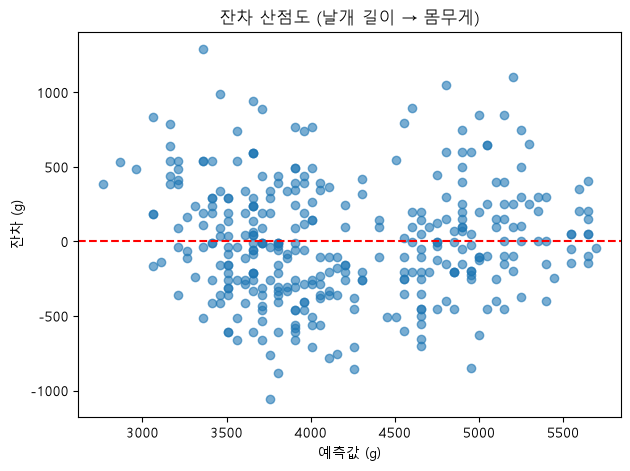

In [38]:
# 문제 5 · Q3
# 여기에 코드를 작성해주세요.
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('잔차 산점도 (날개 길이 → 몸무게)')
plt.xlabel('예측값 (g)')
plt.ylabel('잔차 (g)')
plt.show()

### Q4 · 등분산성을 숫자로 검정해 봅시다

- **브루쉬-페이건 검정**으로 등분산성을 확인하세요.

- H₀는 "등분산이다"입니다. p-값이 0.05보다 작으면 이분산을 의심합니다.

- 판정 결과를 문장으로 함께 출력하세요.

- `💡 힌트` `het_breuschpagan(잔차, model.model.exog)`는
  `(LM통계량, LM p-값, F통계량, F p-값)`을 돌려줍니다.

In [39]:
# 문제 5 · Q4
# 여기에 코드를 작성해주세요.
from statsmodels.stats.diagnostic import het_breuschpagan

alpha = 0.05
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(resid, model.model.exog)

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"

print(f"LM 통계량 = {bp_lm:.4f}, p-value {fmt_p(bp_p)}")

if bp_p < alpha:
    print("→ 귀무가설(등분산)을 기각한다. 이분산이 의심되므로 p-값과 신뢰구간을 그대로 믿기 어렵다.")
else:
    print("→ 귀무가설(등분산)을 기각하지 못한다. 이분산이라는 근거가 부족하므로 등분산 가정을 유지한다.")

LM 통계량 = 2.1579, p-value = 0.142
→ 귀무가설(등분산)을 기각하지 못한다. 이분산이라는 근거가 부족하므로 등분산 가정을 유지한다.


### Q5 · 문제가 있는 모형과 나란히 비교해 봅시다

- **비교군**으로 `body_mass_g ~ bill_length_mm` 모형을 적합해 `model_bill`로 저장하세요.

- 두 모형의 잔차 산점도를 **나란히** 그리세요.

- 두 모형의 브루쉬-페이건 p-값을 **함께 출력**해 비교하세요.

- `💡 힌트` `fig, ax = plt.subplots(1, 2, figsize=(12, 4))`로 두 그림을 옆으로 배치할 수 있습니다.

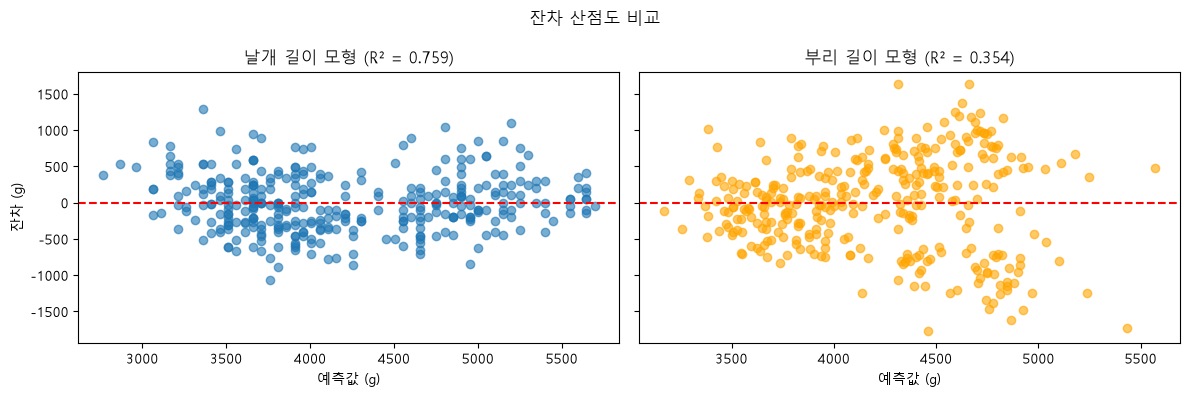

              R²  BP p-value      판정
날개 길이 모형  0.7590      0.1418  등분산 유지
부리 길이 모형  0.3542      0.0000  이분산 의심


In [40]:
# 문제 5 · Q5
# 여기에 코드를 작성해주세요.
# 비교군 모형: 부리 길이 → 몸무게
df_bill = penguins.dropna(subset=['body_mass_g', 'bill_length_mm'])
model_bill = smf.ols(formula='body_mass_g ~ bill_length_mm', data=df_bill).fit()

resid_bill = model_bill.resid
fitted_bill = model_bill.fittedvalues

# 잔차 산점도를 나란히 그리기
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax[0].scatter(fitted, resid, alpha=0.6)
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_title(f'날개 길이 모형 (R² = {model.rsquared:.3f})')
ax[0].set_xlabel('예측값 (g)')
ax[0].set_ylabel('잔차 (g)')

ax[1].scatter(fitted_bill, resid_bill, alpha=0.6, color='orange')
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title(f'부리 길이 모형 (R² = {model_bill.rsquared:.3f})')
ax[1].set_xlabel('예측값 (g)')

plt.suptitle('잔차 산점도 비교')
plt.tight_layout()
plt.show()

# 브루쉬-페이건 p-값 비교
_, bp_p_bill, _, _ = het_breuschpagan(resid_bill, model_bill.model.exog)

compare_bp = pd.DataFrame({
    'R²': [model.rsquared, model_bill.rsquared],
    'BP p-value': [bp_p, bp_p_bill],
    '판정': ['이분산 의심' if p < alpha else '등분산 유지' for p in [bp_p, bp_p_bill]]
}, index=['날개 길이 모형', '부리 길이 모형'])

print(compare_bp.round(4))

### Q6 · 보고 문장으로 정리해 봅시다

- 지금까지의 결과를 종합해, 우리 회귀모형을 보고서에 어떻게 적을지 **한 문장**으로 쓰세요.

- **기울기 + 유의성 + 설명력 + 진단 결과**를 모두 담아 보세요.

In [45]:
# 문제 5 · Q6
# 보고 문장:
# 문제 5 · Q6
# 문제 5 · Q6
a = model.params['Intercept']
b = model.params['flipper_length_mm']
p_b = model.pvalues['flipper_length_mm']
r2 = model.rsquared

print(f'''
회귀식 '몸무게(g) = {a:.2f} + {b:.2f} × 날개 길이(mm)'에 따르면 날개 길이가 1mm 더 긴 펭귄은 몸무게가 평균적으로 약 {b:.2f}g 더 무거웠으며, 
이 기울기는 통계적으로 유의하였고(p {fmt_p(p_b)}), 모형은 몸무게 분산의 약 {r2*100:.1f}%를 설명하였다. 
또한 브루쉬-페이건 검정 결과 등분산 가정이 기각되지 않아(p {fmt_p(bp_p)}) 등분산 가정을 위배한다는 근거는 없었다.
''')


회귀식 '몸무게(g) = -5780.83 + 49.69 × 날개 길이(mm)'에 따르면 날개 길이가 1mm 더 긴 펭귄은 몸무게가 평균적으로 약 49.69g 더 무거웠으며, 
이 기울기는 통계적으로 유의하였고(p < 0.001), 모형은 몸무게 분산의 약 75.9%를 설명하였다. 
또한 브루쉬-페이건 검정 결과 등분산 가정이 기각되지 않아(p = 0.142) 등분산 가정을 위배한다는 근거는 없었다.



### 💬 정리 · 결과를 말로 설명해 보기

- Q3·Q4에서 우리 모형의 잔차는 어떤 상태였나요? 이 결과를 근거로 문제 3·4의 해석을 신뢰할 수 있을까요?

- Q5의 두 잔차 산점도는 어떻게 달랐나요? 비교군에서 관찰된 모양을 강의에서 배운 용어로 무엇이라 부르나요?

- 비교군처럼 등분산성이 깨졌을 때, **잘못된 것은 기울기 값 자체인가요, 아니면 그 값의 통계적 해석인가요?**

- R²가 1이 아니라는 것은 설명되지 않은 변동이 남아 있다는 뜻입니다. `penguins` 안에서 몸무게에 영향을 줄 만한데 우리 모델이 놓치고 있는 변수는 무엇일까요?

- 그 변수들을 모델에 함께 넣으려면 어떤 분석이 필요할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 7장은 이렇게 적었습니다 — _"파라미터 값이 잘못되었다는 뜻이 아니라, 이 값의 통계적 해석(유의성·신뢰구간)과 예측 결과를 신뢰할 수 없다는 의미"_. 세 번째 질문의 답이 여기 있습니다.

- 비교군의 잔차가 퍼지는 모양을 강의의 3케이스 그림(정규성 O·등분산 O / X·O / O·X)과 맞춰 보세요.

- 놓친 변수 후보는 문제 1의 그림에 이미 있습니다. 그 변수를 모델에 함께 넣는 분석의 이름은 다음 8장의 제목입니다.

</details>

In [ ]:
# 문제 5 · 정리
# 여기에 의견을 작성해주세요.
print('''
1. 우리 모형의 잔차는 0을 중심으로 위아래로 고르게 퍼져 있었고, 깔때기나 곡선 같은 뚜렷한 패턴이 보이지 않았다.
브루쉬-페이건 검정에서도 p = 0.142로 등분산 가정을 기각하지 못해, 이분산이라는 근거가 없었다.
따라서 문제 3의 기울기 해석과 문제 4의 유의성 검정 결과(t값, p-값)는 등분산 가정 측면에서 신뢰할 수 있다.

2. 우리 모형은 잔차가 고르게 퍼져 있었지만 비교군은 예측값이 커질수록 잔차가 넓게 퍼지는 깔때기 모양이었다.
브루쉬-페이건 검정에서도 p-값이 0.05보다 작아 등분산 가정이 기각되었다.
이처럼 잔차의 퍼짐 정도가 일정하지 않은 상태를 이분산성이라고 하며 강의의 3케이스 중 '정규성 O · 등분산성 X'에 해당한다.

3. 등분산성이 깨졌을 때 잘못되는 것은 기울기 값 자체가 아니라 그 값의 통계적 해석이다.
기울기는 b = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)²로 계산되며 이 식에는 등분산 가정이 쓰이지 않으므로 값 자체는 그대로 믿을 수 있다.
그러나 기울기의 표준오차 SE(b) = σ / √Σ(x − x̄)²는 '모든 x에서 잔차의 퍼짐(σ)이 같다'는 등분산 가정을 전제로 계산된다.
이분산이 있으면 SE가 틀리고, 그에 따라 t값, p-값, 신뢰구간, 예측구간도 모두 신뢰할 수 없게 된다.
즉 기울기 값 자체는 믿을 수 있지만 그 기울기(표준오차, t값, p-값, 신뢰구간)가 얼마나 확실한지는 믿을 수 없게 된다.

4. 종(species)이 대표적이다. 
이 밖에 성별, 부리 길이와 부리 두께, 서식 섬도 몸무게에 영향을 줄 수 있는 변수이다.

5. 설명변수를 여러 개 함께 넣는 다중회귀분석(Multiple Regression)이 필요하다.
(종과 성별처럼 범주형 변수는 더미 변수(0/1)로 바꾸어 넣어야 한다.
다중회귀에서 날개 길이의 기울기는 '종과 성별이 같은 펭귄끼리 비교했을 때'의 차이를 뜻하므로,
교란변수를 통제한 상태에서 날개 길이와 몸무게의 관계를 볼 수 있다.)
''')